Загрузка данных и настройка:

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
# Импортируем обе функции для метрик
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import xgboost as xgb
import joblib

# Загружаем подготовленные данные
train = pd.read_csv("../data/processed/train.csv", parse_dates=["date"])
test  = pd.read_csv("../data/processed/test.csv",  parse_dates=["date"])

# Список признаков
FEATURES = ["lag_1", "lag_2", "lag_3", "lag_12", "rolling_mean_3", "rolling_std_3", "month", "quarter", "year"]
TARGET = "demand_tons"

# Функции для расчета метрик
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def evaluate(name, y_true, y_pred):
    return {
        "model": name,
        "MAE": round(mean_absolute_error(y_true, y_pred), 2),
        # Используем новую функцию root_mean_squared_error
        "RMSE": round(root_mean_squared_error(y_true, y_pred), 2),
        "MAPE_%": round(mape(y_true, y_pred), 2)
    }

results = [] # Сюда будем складывать результаты

Базовая модель (Naive forecast):

In [4]:
results.append(evaluate("Naive (lag_1)", test[TARGET], test["lag_1"]))
print("Базовая модель рассчитана.")

Базовая модель рассчитана.


Линейная регрессия (Baseline ML):

In [5]:
lr = LinearRegression()
lr.fit(train[FEATURES], train[TARGET])
pred_lr = lr.predict(test[FEATURES])
results.append(evaluate("LinearRegression", test[TARGET], pred_lr))
print("LinearRegression обучена.")

LinearRegression обучена.


Random Forest:

In [6]:
rf = RandomForestRegressor(n_estimators=300, max_depth=7, random_state=42)
rf.fit(train[FEATURES], train[TARGET])
pred_rf = rf.predict(test[FEATURES])
results.append(evaluate("RandomForest", test[TARGET], pred_rf))
print("RandomForest обучен.")

RandomForest обучен.


XGBoost (Улучшенная модель):

In [7]:
xgb_model = xgb.XGBRegressor(
    n_estimators=300, 
    max_depth=4, 
    learning_rate=0.05,
    random_state=42
)
xgb_model.fit(train[FEATURES], train[TARGET])
pred_xgb = xgb_model.predict(test[FEATURES])
results.append(evaluate("XGBoost", test[TARGET], pred_xgb))
print("XGBoost обучен.")

XGBoost обучен.


Сравнение результатов:

In [8]:
summary = pd.DataFrame(results).sort_values("MAPE_%")
display(summary)

,model,MAE,RMSE,MAPE_%
1,LinearRegression,37.12,52.42,4.04
2,RandomForest,59.37,80.00,6.61
3,XGBoost,63.94,83.87,7.07
0,Naive (lag_1),110.83,149.34,11.43


Визуализация прогноза:

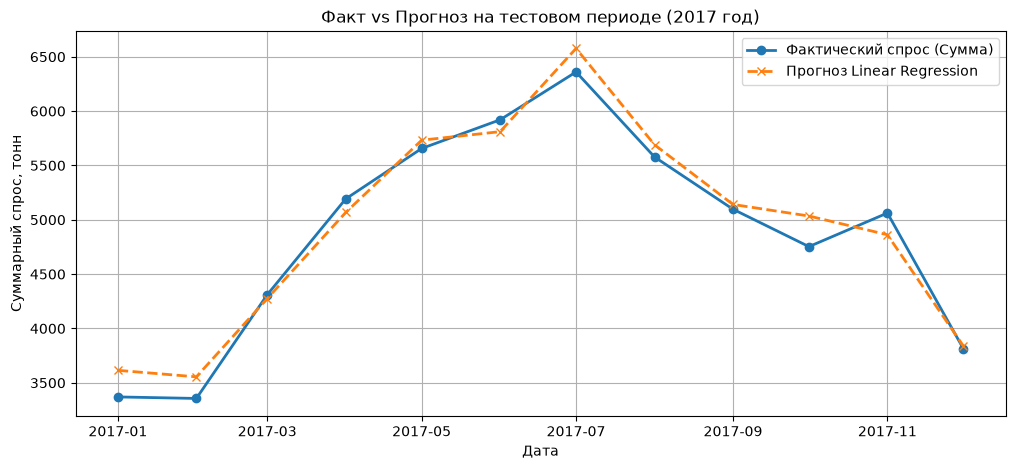

In [9]:
# Добавляем прогноз лучшей модели (LinearRegression) в тестовый датасет
test_plot = test.copy()
test_plot["pred_best"] = pred_lr  # Используем прогноз линейной регрессии

# Группируем по датам (суммируем спрос по всем 5 товарам)
agg_actual = test_plot.groupby("date")[TARGET].sum()
agg_pred = test_plot.groupby("date")["pred_best"].sum()

plt.figure(figsize=(12, 5))
plt.plot(agg_actual.index, agg_actual.values, marker="o", linewidth=2, label="Фактический спрос (Сумма)")
plt.plot(agg_pred.index, agg_pred.values, marker="x", linestyle="--", linewidth=2, label="Прогноз Linear Regression")
plt.title("Факт vs Прогноз на тестовом периоде (2017 год)")
plt.xlabel("Дата")
plt.ylabel("Суммарный спрос, тонн")
plt.legend()
plt.grid(True)
plt.show()

Важность признаков (для Линейной регрессии).
Для линейных моделей важность признаков определяется по модулю их коэффициентов (чем больше коэффициент, тем сильнее признак влияет на прогноз).

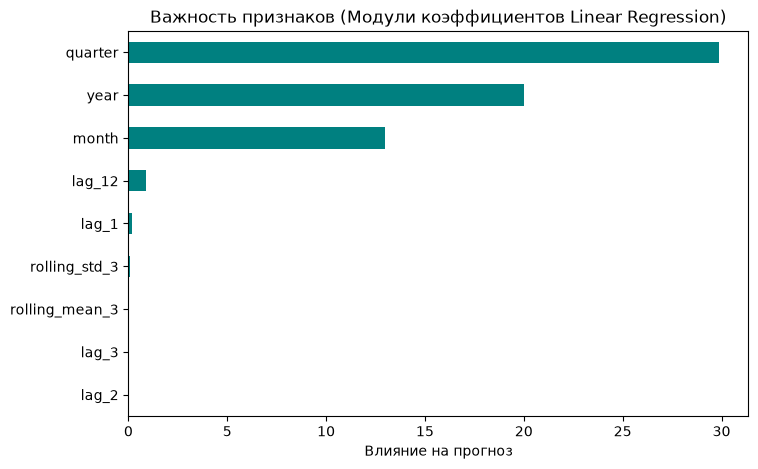

In [10]:
# Получаем коэффициенты линейной регрессии
coefs = pd.Series(lr.coef_, index=FEATURES).abs().sort_values(ascending=True)

plt.figure(figsize=(8, 5))
coefs.plot(kind="barh", color="teal")
plt.title("Важность признаков (Модули коэффициентов Linear Regression)")
plt.xlabel("Влияние на прогноз")
plt.show()

Сохранение модели:

In [11]:
import os
os.makedirs("../models", exist_ok=True)

# Сохраняем лучшую модель (LinearRegression)
joblib.dump({"model": lr, "features": FEATURES}, "../models/best_demand_model.pkl")
print("Модель Linear Regression успешно сохранена в папку models/")

Модель Linear Regression успешно сохранена в папку models/
